In [2]:
%run 1_data_exploration.ipynb
print (y)

NumPy: 2.5.4
pandas: 3.1.0
Number of rows: 319
Number of columns: 39
Dataset shape: (319, 39)
Dataset datatypes:
Gallstone Status                                    int64
Age                                                 int64
Gender                                              int64
Comorbidity                                         int64
Coronary Artery Disease (CAD)                       int64
Hypothyroidism                                      int64
Hyperlipidemia                                      int64
Diabetes Mellitus (DM)                              int64
Height                                              int64
Weight                                            float64
Body Mass Index (BMI)                             float64
Total Body Water (TBW)                            float64
Extracellular Water (ECW)                         float64
Intracellular Water (ICW)                         float64
Extracellular Fluid/Total Body Water (ECF/TBW)    float64
Total Body Fat Ra

# Model selection and training
Compares three models on the same split, CV scheme and metric (ROC AUC):
1. Logistic Regression
2. Logistic Regression + log features
3. XGBoost

We want to test data based on simple logistic regression. However, We have skewed features (explained in cleaning) that are skewed at it's tail. So We are going to test it against Logistic with log  features. Using log should decrease skewness. (Result will uphold the theory). And a XG Boost model as these models do not depend on how skew the value is they are best models to test against Logistic models

Data cleaning and exploration are done in `1_`, validation in `3_`.

# Import dependencies

We are using sklearn to import logistic regression, and xgboost

In [1]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import (ParameterGrid, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_score,
                                     cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier

print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")

NumPy: 2.5.4
pandas: 3.1.0


# Load dataset and split

We are dividing data set 80/20 rule, for training We are using 80 percent of data for training and 20 percent for testing.

In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (255, 38), Test: (64, 38)


# Models and hyperparameter grids

Logistic Regression: C sets regularization strength
Logistic Regression + log: same C, but skewed features are first transformed with log1p before scaling.
XGBoost: We define number of trees, tree complexity learning rate 

In [28]:
def make_model(name, **params):
    if name == "logreg":
        return make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000, **params),
        )
    if name == "logreg + log":
        return make_pipeline(
            ColumnTransformer([("log", FunctionTransformer(np.log1p), skewed)],
                              remainder="passthrough"),
            StandardScaler(),
            LogisticRegression(max_iter=5000, **params),
        )
    return XGBClassifier(eval_metric="logloss", random_state=42, **params)


C_grid = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
grids = {
    "logreg": {"C": C_grid},
    "logreg + log": {"C": C_grid},
"xgboost": {"max_depth": [3, 4],
            "learning_rate": [0.003, 0.01],
            "n_estimators": [30, 100, 300, 1000],},
}

# Tune with cross-validation (training set only)

using Cross-Validation before training.Cross-validation is a way to estimate how well a model will perform on unseen data by repeatedly training on part of the training set and validating on the part held out. We splitting in 5 equal parts

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_params = {}

for name, grid in grids.items():
    print(f"\n=== {name} ===")
    best_auc = -1
    for params in ParameterGrid(grid):
        scores = cross_validate(make_model(name, **params), X_train, y_train,
                                cv=cv, scoring=["accuracy", "roc_auc", "f1"])
        auc = scores["test_roc_auc"].mean()
        summary = "  ".join(
            f"{m}: {scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}"
            for m in ["accuracy", "roc_auc", "f1"])
        print(f"{params}\n    {summary}")
        
        if auc > best_auc:
            best_auc, best_params[name] = auc, params
    print(f"Best (by CV ROC AUC): {best_params[name]} -> {best_auc:.3f}")


=== logreg ===
{'C': 0.001}
    accuracy: 0.608 ± 0.089  roc_auc: 0.702 ± 0.113  f1: 0.570 ± 0.101
{'C': 0.01}
    accuracy: 0.694 ± 0.077  roc_auc: 0.770 ± 0.093  f1: 0.666 ± 0.084
{'C': 0.1}
    accuracy: 0.737 ± 0.051  roc_auc: 0.813 ± 0.071  f1: 0.711 ± 0.058
{'C': 1}
    accuracy: 0.741 ± 0.074  roc_auc: 0.830 ± 0.066  f1: 0.716 ± 0.083
{'C': 10}
    accuracy: 0.741 ± 0.062  roc_auc: 0.816 ± 0.058  f1: 0.719 ± 0.072
{'C': 100}
    accuracy: 0.737 ± 0.063  roc_auc: 0.805 ± 0.063  f1: 0.717 ± 0.066
{'C': 1000}
    accuracy: 0.725 ± 0.058  roc_auc: 0.801 ± 0.061  f1: 0.705 ± 0.062
Best (by CV ROC AUC): {'C': 1} -> 0.830

=== logreg + log ===
{'C': 0.001}
    accuracy: 0.651 ± 0.092  roc_auc: 0.766 ± 0.098  f1: 0.621 ± 0.096
{'C': 0.01}
    accuracy: 0.765 ± 0.071  roc_auc: 0.833 ± 0.071  f1: 0.752 ± 0.070
{'C': 0.1}
    accuracy: 0.788 ± 0.077  roc_auc: 0.866 ± 0.051  f1: 0.766 ± 0.082
{'C': 1}
    accuracy: 0.824 ± 0.058  roc_auc: 0.866 ± 0.049  f1: 0.815 ± 0.058
{'C': 10}
    accu

,learning_rate,max_depth,n_estimators,ROC AUC mean,ROC AUC std,Accuracy mean,Accuracy std
3,0.003,3,1000,0.844,0.083,0.788,0.080
27,0.100,3,1000,0.844,0.042,0.757,0.044
10,0.010,3,300,0.844,0.082,0.796,0.071
17,0.030,3,100,0.843,0.085,0.792,0.076
31,0.100,4,1000,0.841,0.046,0.776,0.044
14,0.010,4,300,0.840,0.082,0.773,0.056
19,0.030,3,1000,0.840,0.047,0.757,0.063
26,0.100,3,300,0.840,0.052,0.761,0.049
7,0.003,4,1000,0.838,0.079,0.773,0.058
30,0.100,4,300,0.836,0.058,0.773,0.053


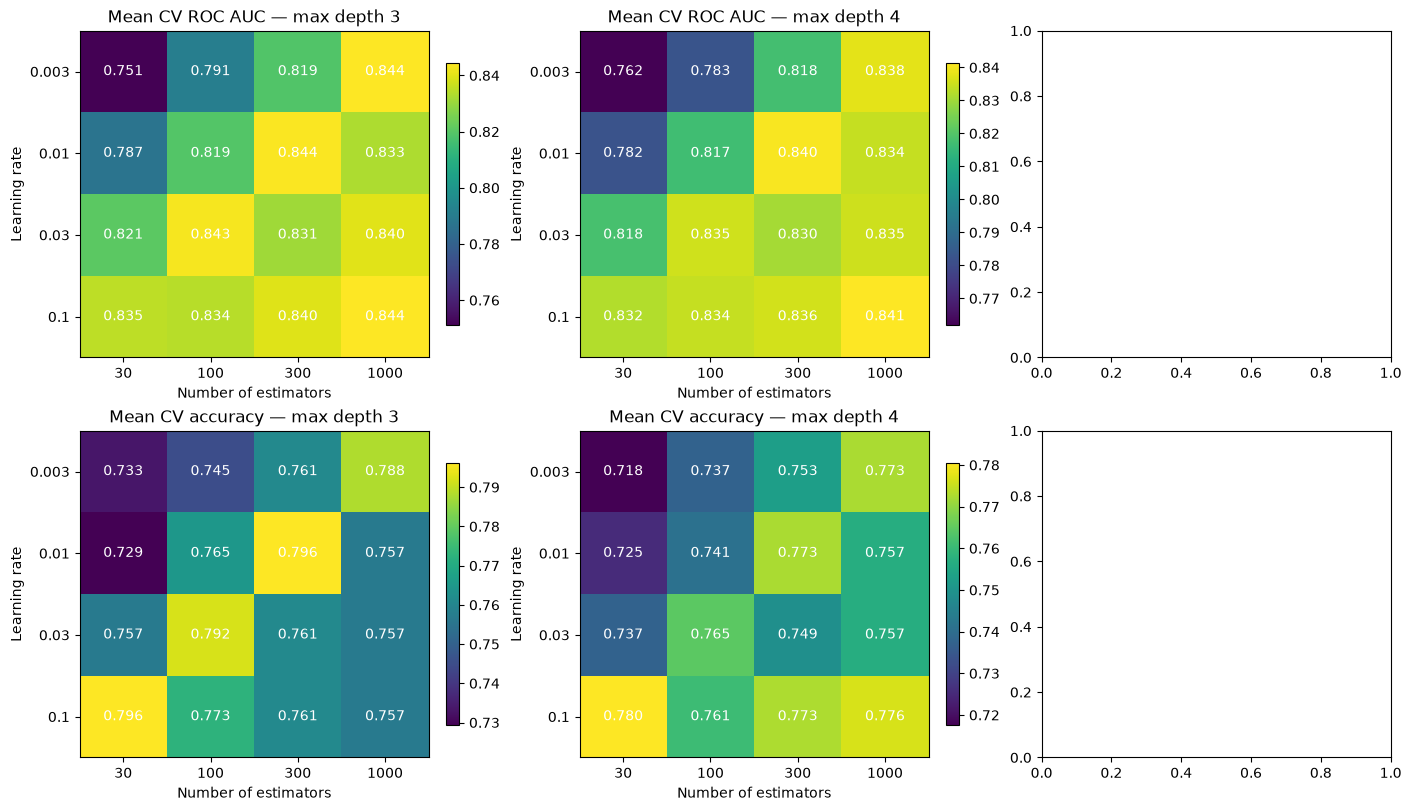

In [24]:
xgb_tuning_rows = []

for params in ParameterGrid(grids["xgboost"]):
    cv_scores = cross_validate(
        make_model("xgboost", **params),
        X_train,
        y_train,
        cv=cv,
        scoring=["roc_auc", "accuracy"],
    )
    xgb_tuning_rows.append({
        **params,
        "ROC AUC mean": cv_scores["test_roc_auc"].mean(),
        "ROC AUC std": cv_scores["test_roc_auc"].std(),
        "Accuracy mean": cv_scores["test_accuracy"].mean(),
        "Accuracy std": cv_scores["test_accuracy"].std(),
    })

xgb_tuning_results = pd.DataFrame(xgb_tuning_rows)
display(xgb_tuning_results.sort_values("ROC AUC mean", ascending=False).round(3))

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)

for row, (metric, title) in enumerate([
    ("ROC AUC mean", "Mean CV ROC AUC"),
    ("Accuracy mean", "Mean CV accuracy"),
]):
    for col, depth in enumerate(sorted(xgb_tuning_results["max_depth"].unique())):
        ax = axes[row, col]
        matrix = (
            xgb_tuning_results[xgb_tuning_results["max_depth"] == depth]
            .pivot(index="learning_rate", columns="n_estimators", values=metric)
            .sort_index()
        )

        image = ax.imshow(matrix.values, aspect="auto", cmap="viridis")
        ax.set_xticks(range(len(matrix.columns)), labels=matrix.columns)
        ax.set_yticks(range(len(matrix.index)), labels=matrix.index)
        ax.set_xlabel("Number of estimators")
        ax.set_ylabel("Learning rate")
        ax.set_title(f"{title} — max depth {depth}")

        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                ax.text(j, i, f"{matrix.iloc[i, j]:.3f}",
                        ha="center", va="center", color="white")

        fig.colorbar(image, ax=ax, shrink=0.8)

plt.show()

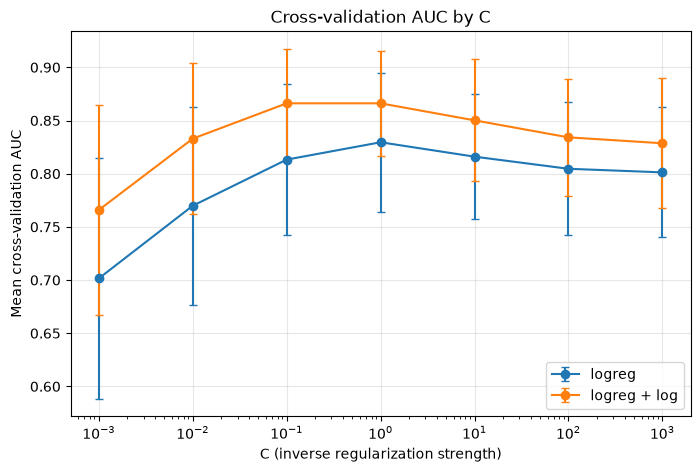

In [30]:
import matplotlib.pyplot as plt

cv_accuracy = {}

for name in ["logreg", "logreg + log"]:
    means, stds = [], []
    for C in C_grid:
        scores = cross_val_score(
            make_model(name, C=C),
            X_train,
            y_train,
            cv=cv,
            scoring="roc_auc",
        )
        means.append(scores.mean())
        stds.append(scores.std())
    cv_accuracy[name] = (means, stds)

fig, ax = plt.subplots(figsize=(8, 5))
for name, (means, stds) in cv_accuracy.items():
    ax.errorbar(C_grid, means, yerr=stds, marker="o", capsize=3, label=name)

ax.set_xscale("log")
ax.set_xlabel("C (inverse regularization strength)")
ax.set_ylabel("Mean cross-validation AUC")
ax.set_title("Cross-validation AUC by C")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()